## Project Title: Netflix Movie Recommendation Strategies
Business Question:

How could Netflix recommend content based on viewer preferences?

Project Overview:

This project explores Netflix user information, movie characteristics and viewing history to understand viewer preferences and develop a basic movie recommendation strategy.

The analysis uses Python, Pandas, NumPy and data visualization techniques to identify viewing patterns, movie preferences and potential recommendations.

Project Objectives:
1. Examine Netflix user and movie datasets.
2. Clean and prepare the available data.
3. Explore movie ratings and viewing behaviour.
4. Identify popular movie genres.
5. Develop business insights to support recommendation strategies.

In [1]:
# Import the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display all columns
pd.set_option("display.max_columns", None)

# Set visualization style
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load the Netflix datasets

users = pd.read_csv("DATA/users.csv")
movies = pd.read_csv("DATA/movies.csv")
watch_history = pd.read_csv("DATA/watch_history.csv")

print("All three Netflix datasets loaded successfully!")

All three Netflix datasets loaded successfully!


In [3]:
# Display the first five records

print("USERS DATASET")
display(users.head(10))

print("MOVIES DATASET")
display(movies.head(10))

print("WATCH HISTORY DATASET")
display(watch_history.head(10))

USERS DATASET


,user_id,name,date_of_birth,address
0,1,Ama Mensah,1998-04-12,"Accra, Ghana"
1,2,Kwame Boateng,1995-09-23,"Kumasi, Ghana"
2,3,Michael Appiah,1997-01-15,"Heidelberg, Germany"
3,4,Sarah Johnson,2000-06-08,"London, UK"
4,5,Daniel Okafor,1994-11-30,"Lagos, Nigeria"
5,6,Fatima Hassan,1999-02-17,"Abu Dhabi, UAE"
6,7,Josephine Clark,1996-07-21,"Manchester, UK"
7,8,Kofi Asare,2001-03-05,"Cape Coast, Ghana"
8,9,Linda Chen,1993-12-14,"Berlin, Germany"
9,10,Peter Mwangi,1998-08-29,"Nairobi, Kenya"


MOVIES DATASET


,movie_id,title,Genre,Year,Avg_rating
0,101,The Last Horizon,Adventure,2021,8.1
1,102,Midnight Letters,Drama,2019,7.6
2,103,Code of Tomorrow,Sci-Fi,2023,8.4
3,104,A Summer in Paris,Romance,2020,7.2
4,105,The Hidden Truth,Thriller,2018,7.9
5,106,Laugh Out Loud,Comedy,2022,6.9
6,107,Kingdom of Ash,Fantasy,2024,8.0
7,108,Beyond the Goal,Sport,2017,7.4
8,109,Silent Witness,Crime,2021,8.2
9,110,Ocean Wonders,Documentary,2023,8.7


WATCH HISTORY DATASET


,movie_id,User_id,date,rating
0,101,1,01-10-26,8
1,103,1,04-10-26,9
2,102,2,02-10-26,7
3,105,2,06-10-26,8
4,104,3,03-10-26,7
5,107,3,08-10-26,9
6,106,4,05-10-26,6
7,109,5,07-10-26,9
8,110,6,09-10-26,10
9,108,7,10-10-26,8


In [4]:
# Check the dimensions of each dataset

print("Users:", users.shape)

print("Movies:", movies.shape)

print("Watch History:", watch_history.shape)

Users: (10, 4)
Movies: (10, 5)
Watch History: (10, 4)


In [5]:
# Check information about each dataset

print("USERS INFORMATION")
users.info()

print("\nMOVIES INFORMATION")
movies.info()

print("\nWATCH HISTORY INFORMATION")
watch_history.info()

USERS INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   user_id        10 non-null     int64
 1   name           10 non-null     str  
 2   date_of_birth  10 non-null     str  
 3   address        10 non-null     str  
dtypes: int64(1), str(3)
memory usage: 452.0 bytes

MOVIES INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   movie_id    10 non-null     int64  
 1   title       10 non-null     str    
 2   Genre       10 non-null     str    
 3   Year        10 non-null     int64  
 4   Avg_rating  10 non-null     float64
dtypes: float64(1), int64(2), str(2)
memory usage: 532.0 bytes

WATCH HISTORY INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 4 columns):
 #   Column 

In [6]:
# Check for missing values

print("Missing values in Users:")
print(users.isnull().sum())

print("\nMissing values in Movies:")
print(movies.isnull().sum())

print("\nMissing values in Watch History:")
print(watch_history.isnull().sum())

Missing values in Users:
user_id          0
name             0
date_of_birth    0
address          0
dtype: int64

Missing values in Movies:
movie_id      0
title         0
Genre         0
Year          0
Avg_rating    0
dtype: int64

Missing values in Watch History:
movie_id    0
User_id     0
date        0
rating      0
dtype: int64


In [7]:
# Check for duplicate records

print("Duplicate records in Users:", users.duplicated().sum())

print("Duplicate records in Movies:", movies.duplicated().sum())

print("Duplicate records in Watch History:", watch_history.duplicated().sum())

Duplicate records in Users: 0
Duplicate records in Movies: 0
Duplicate records in Watch History: 0


In [8]:
# Generate descriptive statistics

print("MOVIE STATISTICS")
display(movies.describe())

print("WATCH HISTORY STATISTICS")
display(watch_history.describe())

MOVIE STATISTICS


,movie_id,Year,Avg_rating
count,10.00000,10.000000,10.000000
mean,105.50000,2020.800000,7.840000
std,3.02765,2.299758,0.560159
min,101.00000,2017.000000,6.900000
25%,103.25000,2019.250000,7.450000
50%,105.50000,2021.000000,7.950000
75%,107.75000,2022.750000,8.175000
max,110.00000,2024.000000,8.700000


WATCH HISTORY STATISTICS


,movie_id,User_id,rating
count,10.00000,10.000000,10.000000
mean,105.50000,3.400000,8.100000
std,3.02765,2.065591,1.197219
min,101.00000,1.000000,6.000000
25%,103.25000,2.000000,7.250000
50%,105.50000,3.000000,8.000000
75%,107.75000,4.750000,9.000000
max,110.00000,7.000000,10.000000


Initial Data Quality Assessment

In [9]:
# DATA QUALITY CHECKS

# 1. Check missing values
print("MISSING VALUES")

print("Users:")
print(users.isnull().sum())

print("\nMovies:")
print(movies.isnull().sum())

print("\nWatch History:")
print(watch_history.isnull().sum())


# 2. Check duplicate records
print("\nDUPLICATE RECORDS")

print("Users:", users.duplicated().sum())
print("Movies:", movies.duplicated().sum())
print("Watch History:", watch_history.duplicated().sum())


# 3. Check data types
print("\nDATA TYPES")

print("Users:")
print(users.dtypes)

print("\nMovies:")
print(movies.dtypes)

print("\nWatch History:")
print(watch_history.dtypes)

MISSING VALUES
Users:
user_id          0
name             0
date_of_birth    0
address          0
dtype: int64

Movies:
movie_id      0
title         0
Genre         0
Year          0
Avg_rating    0
dtype: int64

Watch History:
movie_id    0
User_id     0
date        0
rating      0
dtype: int64

DUPLICATE RECORDS
Users: 0
Movies: 0
Watch History: 0

DATA TYPES
Users:
user_id          int64
name               str
date_of_birth      str
address            str
dtype: object

Movies:
movie_id        int64
title             str
Genre             str
Year            int64
Avg_rating    float64
dtype: object

Watch History:
movie_id    int64
User_id     int64
date          str
rating      int64
dtype: object


## 1. Initial Data Quality Assessment

The initial inspection of the three Netflix datasets revealed that each dataset contains 10 records.

The Users dataset contains 4 columns, the Movies dataset contains 5 columns, and the Watch History dataset contains 4 columns.

The missing-value assessment identified no missing values across the datasets. Similarly, the duplicate-record assessment found no completely duplicated rows.

However, the inspection of data types identified that the date_of_birth and date columns were stored as strings rather than datetime objects.

Therefore, additional data preparation is required to convert these columns into appropriate datetime formats and standardize column names before merging the datasets.

Overall, the datasets are sufficiently complete for the next stage of data preparation and exploratory analysis.

In [10]:
# Standardize column names

users.columns = users.columns.str.lower()

movies.columns = movies.columns.str.lower()

watch_history.columns = watch_history.columns.str.lower()

print("Column names standardized successfully!")

print("\nUsers columns:")
print(users.columns.tolist())

print("\nMovies columns:")
print(movies.columns.tolist())

print("\nWatch History columns:")
print(watch_history.columns.tolist())

Column names standardized successfully!

Users columns:
['user_id', 'name', 'date_of_birth', 'address']

Movies columns:
['movie_id', 'title', 'genre', 'year', 'avg_rating']

Watch History columns:
['movie_id', 'user_id', 'date', 'rating']


In [11]:
# Convert date columns into datetime format

users["date_of_birth"] = pd.to_datetime(
    users["date_of_birth"],
    format="%Y-%m-%d"
)

watch_history["date"] = pd.to_datetime(
    watch_history["date"],
    format="%d-%m-%y"
)

print("Date conversion completed successfully!")

Date conversion completed successfully!


In [12]:
# Verify the updated data types

print("USERS DATA TYPES")
print(users.dtypes)

print("\nWATCH HISTORY DATA TYPES")
print(watch_history.dtypes)

USERS DATA TYPES
user_id                   int64
name                        str
date_of_birth    datetime64[us]
address                     str
dtype: object

WATCH HISTORY DATA TYPES
movie_id             int64
user_id              int64
date        datetime64[us]
rating               int64
dtype: object


In [13]:
# Check whether all viewing records have valid user and movie IDs

print(
    "Invalid User IDs:",
    (~watch_history["user_id"].isin(users["user_id"])).sum()
)

print(
    "Invalid Movie IDs:",
    (~watch_history["movie_id"].isin(movies["movie_id"])).sum()
)

Invalid User IDs: 0
Invalid Movie IDs: 0


In [14]:
# Check whether all user IDs exist

invalid_users = (
    ~watch_history["user_id"].isin(users["user_id"])
).sum()

# Check whether all movie IDs exist

invalid_movies = (
    ~watch_history["movie_id"].isin(movies["movie_id"])
).sum()

print("Invalid User IDs:", invalid_users)
print("Invalid Movie IDs:", invalid_movies)

Invalid User IDs: 0
Invalid Movie IDs: 0


In [15]:
# Merge users with watch history

user_watch = pd.merge(
    users,
    watch_history,
    on="user_id",
    how="inner"
)

display(user_watch)

,user_id,name,date_of_birth,address,movie_id,date,rating
0,1,Ama Mensah,1998-04-12,"Accra, Ghana",101,2026-10-01,8
1,1,Ama Mensah,1998-04-12,"Accra, Ghana",103,2026-10-04,9
2,2,Kwame Boateng,1995-09-23,"Kumasi, Ghana",102,2026-10-02,7
3,2,Kwame Boateng,1995-09-23,"Kumasi, Ghana",105,2026-10-06,8
4,3,Michael Appiah,1997-01-15,"Heidelberg, Germany",104,2026-10-03,7
5,3,Michael Appiah,1997-01-15,"Heidelberg, Germany",107,2026-10-08,9
6,4,Sarah Johnson,2000-06-08,"London, UK",106,2026-10-05,6
7,5,Daniel Okafor,1994-11-30,"Lagos, Nigeria",109,2026-10-07,9
8,6,Fatima Hassan,1999-02-17,"Abu Dhabi, UAE",110,2026-10-09,10
9,7,Josephine Clark,1996-07-21,"Manchester, UK",108,2026-10-10,8


In [16]:
# Second merge: Add movie information

netflix_data = pd.merge(
    user_watch,
    movies,
    on="movie_id",
    how="inner"
)

display(netflix_data)

,user_id,name,date_of_birth,address,movie_id,date,rating,title,genre,year,avg_rating
0,1,Ama Mensah,1998-04-12,"Accra, Ghana",101,2026-10-01,8,The Last Horizon,Adventure,2021,8.1
1,1,Ama Mensah,1998-04-12,"Accra, Ghana",103,2026-10-04,9,Code of Tomorrow,Sci-Fi,2023,8.4
2,2,Kwame Boateng,1995-09-23,"Kumasi, Ghana",102,2026-10-02,7,Midnight Letters,Drama,2019,7.6
3,2,Kwame Boateng,1995-09-23,"Kumasi, Ghana",105,2026-10-06,8,The Hidden Truth,Thriller,2018,7.9
4,3,Michael Appiah,1997-01-15,"Heidelberg, Germany",104,2026-10-03,7,A Summer in Paris,Romance,2020,7.2
5,3,Michael Appiah,1997-01-15,"Heidelberg, Germany",107,2026-10-08,9,Kingdom of Ash,Fantasy,2024,8.0
6,4,Sarah Johnson,2000-06-08,"London, UK",106,2026-10-05,6,Laugh Out Loud,Comedy,2022,6.9
7,5,Daniel Okafor,1994-11-30,"Lagos, Nigeria",109,2026-10-07,9,Silent Witness,Crime,2021,8.2
8,6,Fatima Hassan,1999-02-17,"Abu Dhabi, UAE",110,2026-10-09,10,Ocean Wonders,Documentary,2023,8.7
9,7,Josephine Clark,1996-07-21,"Manchester, UK",108,2026-10-10,8,Beyond the Goal,Sport,2017,7.4


In [17]:
# Inspect the combined dataset

print("Combined dataset dimensions:", netflix_data.shape)

print("\nCombined dataset columns:")
print(netflix_data.columns.tolist())

print("\nFirst five records:")
display(netflix_data.head())

Combined dataset dimensions: (10, 11)

Combined dataset columns:
['user_id', 'name', 'date_of_birth', 'address', 'movie_id', 'date', 'rating', 'title', 'genre', 'year', 'avg_rating']

First five records:


,user_id,name,date_of_birth,address,movie_id,date,rating,title,genre,year,avg_rating
0,1,Ama Mensah,1998-04-12,"Accra, Ghana",101,2026-10-01,8,The Last Horizon,Adventure,2021,8.1
1,1,Ama Mensah,1998-04-12,"Accra, Ghana",103,2026-10-04,9,Code of Tomorrow,Sci-Fi,2023,8.4
2,2,Kwame Boateng,1995-09-23,"Kumasi, Ghana",102,2026-10-02,7,Midnight Letters,Drama,2019,7.6
3,2,Kwame Boateng,1995-09-23,"Kumasi, Ghana",105,2026-10-06,8,The Hidden Truth,Thriller,2018,7.9
4,3,Michael Appiah,1997-01-15,"Heidelberg, Germany",104,2026-10-03,7,A Summer in Paris,Romance,2020,7.2


## 2. Dataset Integration and Merging

The three datasets (Users, Movies and Watch History) were successfully integrated using the Pandas merge() function.

First, the Users dataset was merged with the Watch History dataset using the user_id column. The resulting dataset was then merged with the Movies dataset using the movie_id column.

An inner join was applied to retain records with matching user and movie identifiers.

The resulting master dataset contains 10 records and 11 columns, combining customer demographics, viewing history, movie information and user ratings.

This integrated dataset provides a foundation for exploratory data analysis and the development of a basic movie recommendation strategy.

In [18]:
# Count the number of movies watched in each genre

genre_counts = netflix_data["genre"].value_counts()

print("Movie popularity by genre:")
display(genre_counts)

Movie popularity by genre:


genre
Adventure      1
Sci-Fi         1
Drama          1
Thriller       1
Romance        1
Fantasy        1
Comedy         1
Crime          1
Documentary    1
Sport          1
Name: count, dtype: int64

In [19]:
# Calculate average user ratings for each movie

movie_ratings = (
    netflix_data.groupby("title")["rating"]
    .mean()
    .sort_values(ascending=False)
)

print("Movies ranked by user ratings:")
display(movie_ratings)

Movies ranked by user ratings:


title
Ocean Wonders        10.0
Code of Tomorrow      9.0
Silent Witness        9.0
Kingdom of Ash        9.0
The Hidden Truth      8.0
Beyond the Goal       8.0
The Last Horizon      8.0
A Summer in Paris     7.0
Midnight Letters      7.0
Laugh Out Loud        6.0
Name: rating, dtype: float64

In [20]:
# Count the number of movies watched by each user

user_activity = (
    netflix_data.groupby("name")["movie_id"]
    .count()
    .sort_values(ascending=False)
)

print("User viewing activity:")
display(user_activity)

User viewing activity:


name
Ama Mensah         2
Michael Appiah     2
Kwame Boateng      2
Fatima Hassan      1
Daniel Okafor      1
Josephine Clark    1
Sarah Johnson      1
Name: movie_id, dtype: int64

In [21]:
# Calculate the overall average user rating

overall_rating = netflix_data["rating"].mean()

print("Overall average user rating:", round(overall_rating, 2))

Overall average user rating: 8.1


In [22]:
# Compare user ratings with movie average ratings

rating_comparison = netflix_data[
    ["title", "rating", "avg_rating"]
]

display(rating_comparison)

,title,rating,avg_rating
0,The Last Horizon,8,8.1
1,Code of Tomorrow,9,8.4
2,Midnight Letters,7,7.6
3,The Hidden Truth,8,7.9
4,A Summer in Paris,7,7.2
5,Kingdom of Ash,9,8.0
6,Laugh Out Loud,6,6.9
7,Silent Witness,9,8.2
8,Ocean Wonders,10,8.7
9,Beyond the Goal,8,7.4


## 3. Exploratory Data Analysis

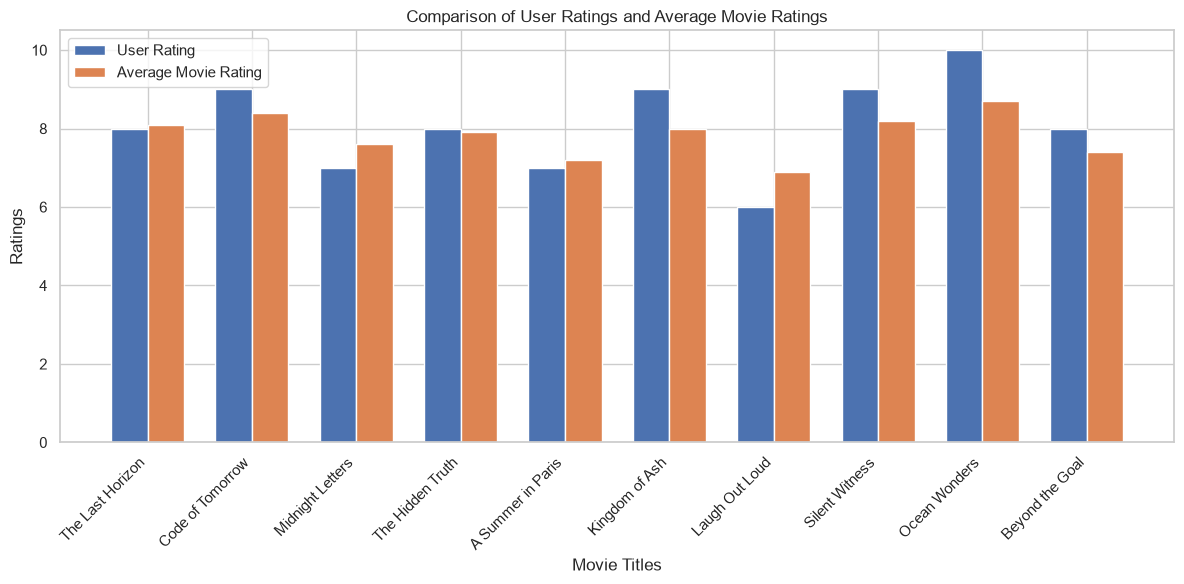

In [23]:
# Compare user ratings with average movie ratings

plt.figure(figsize=(12, 6))

x = np.arange(len(rating_comparison))
width = 0.35

plt.bar(
    x - width/2,
    rating_comparison["rating"],
    width,
    label="User Rating"
)

plt.bar(
    x + width/2,
    rating_comparison["avg_rating"],
    width,
    label="Average Movie Rating"
)

plt.xlabel("Movie Titles")
plt.ylabel("Ratings")

plt.title("Comparison of User Ratings and Average Movie Ratings")

plt.xticks(
    x,
    rating_comparison["title"],
    rotation=45,
    ha="right"
)

plt.legend()
plt.tight_layout()

plt.show()

### 3.1 Interpretation of Movie Ratings Comparison ##

The chart compares individual user ratings with the average ratings of each movie. The results show that individual ratings are generally close to the average movie ratings.

Ocean Wonders recorded the highest individual rating of 10, while Laugh Out Loud recorded the lowest rating of 6. Some movies received individual ratings above their average ratings, while others received ratings below their averages.

This comparison helps identify differences between individual viewing experiences and the overall ratings of movies.

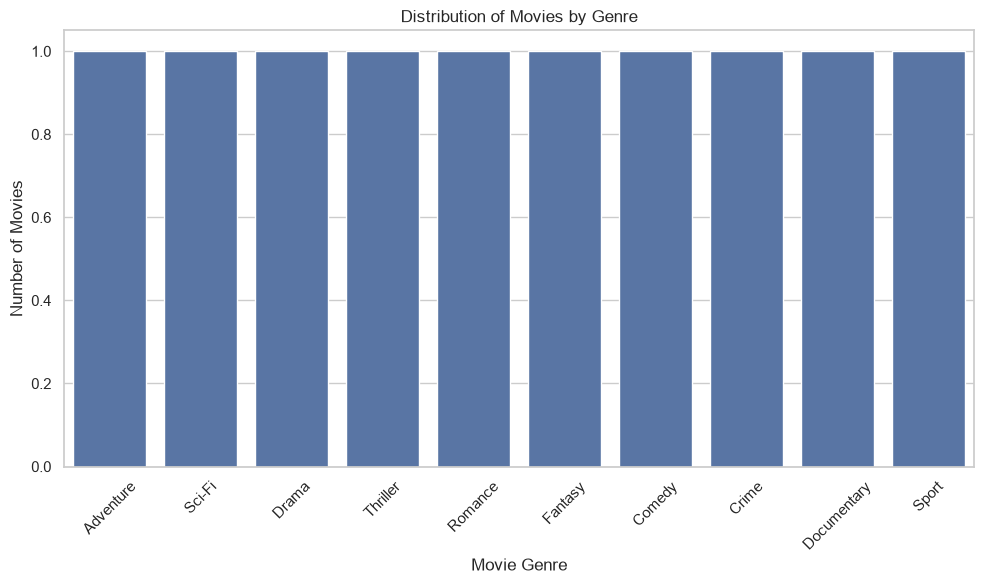

In [24]:
# Visualize movie popularity by genre

plt.figure(figsize=(10, 6))

genre_counts = netflix_data["genre"].value_counts()

sns.barplot(
    x=genre_counts.index,
    y=genre_counts.values
)

plt.title("Distribution of Movies by Genre")
plt.xlabel("Movie Genre")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### 3.2 Interpretation of Movie Popularity by Genre

The chart illustrates the distribution of movies across different genres in the dataset.

The results show that all ten genres are equally represented, with each genre containing one movie.

This indicates that no particular genre dominates the dataset. However, since the dataset contains only ten movies, a larger dataset would be required to establish meaningful patterns in genre popularity.

Overall, the distribution provides a balanced representation of different movie genres for the initial analysis.

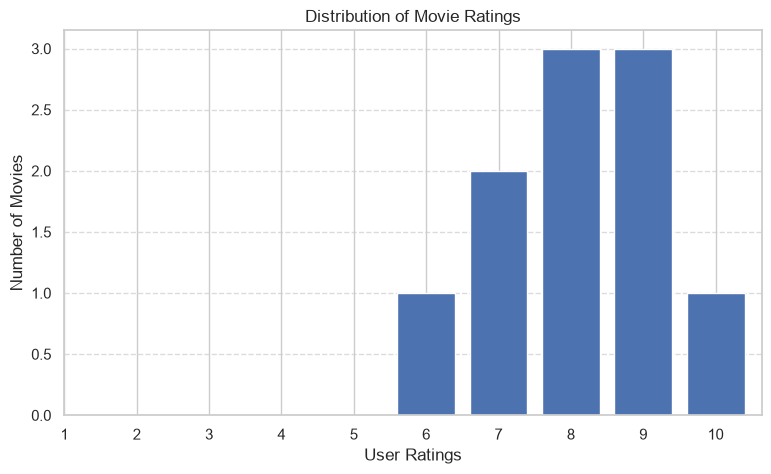

In [25]:
# Distribution of movie ratings

rating_counts = netflix_data["rating"].value_counts().sort_index()

plt.figure(figsize=(9, 5))

plt.bar(
    rating_counts.index,
    rating_counts.values
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("User Ratings")
plt.ylabel("Number of Movies")
plt.xticks(range(1, 11))
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.show()

### 3.3 Interpretation of Movie Ratings Distribution

The chart illustrates the distribution of user ratings across the ten movies in the dataset.

The results show that ratings of 8 and 9 were the most frequent, with three movies each. Ratings of 7 occurred twice, while ratings of 6 and 10 occurred once each.

The majority of the movies received relatively high ratings, indicating generally positive viewing experiences among the users.

The overall average user rating of 8.1 further supports this observation.

Overall, the distribution suggests a positive response to the movies included in the dataset.

In [26]:
# Calculate average user ratings by genre

genre_ratings = (
    netflix_data.groupby("genre")["rating"]
    .mean()
    .sort_values(ascending=False)
)

print("Average User Ratings by Genre:")
display(genre_ratings)

Average User Ratings by Genre:


genre
Documentary    10.0
Crime           9.0
Fantasy         9.0
Sci-Fi          9.0
Thriller        8.0
Adventure       8.0
Sport           8.0
Drama           7.0
Romance         7.0
Comedy          6.0
Name: rating, dtype: float64

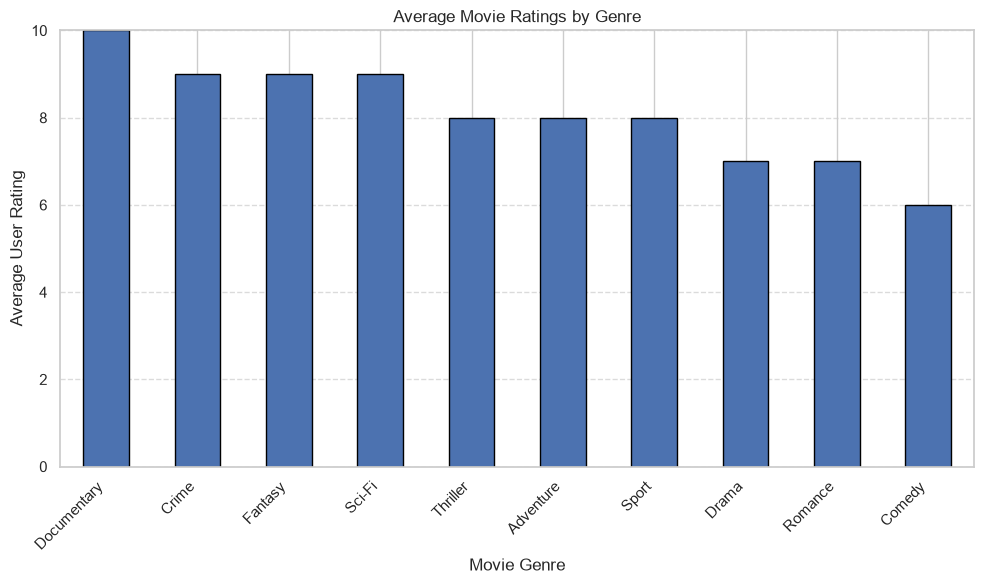

In [27]:
# Visualize average ratings by genre

plt.figure(figsize=(10, 6))

genre_ratings.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Average Movie Ratings by Genre")
plt.xlabel("Movie Genre")
plt.ylabel("Average User Rating")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 10)
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

### 3.4 Interpretation of Average Movie Ratings by Genre

The chart compares the average user ratings across the ten movie genres in the dataset.

The results indicate that Documentary recorded the highest average rating of 10, followed by Crime, Fantasy and Sci-Fi, which each received a rating of 9.

Thriller, Adventure and Sport recorded ratings of 8, while Drama and Romance received ratings of 7. Comedy recorded the lowest rating of 6.

These findings suggest that Documentary, Crime, Fantasy and Sci-Fi received the most favourable ratings among the movies included in the dataset.

However, each genre contains only one movie. Therefore, these results represent the ratings of individual movies rather than the overall popularity or quality of their respective genres. A larger dataset would be necessary to establish more reliable genre-level comparisons.

### 3.5 User Viewing Activity

This analysis examines the number of movies watched by each user. 
It helps identify the most active viewers and understand viewing 
activity across the platform.

User Viewing Activity:


name
Ama Mensah         2
Michael Appiah     2
Kwame Boateng      2
Fatima Hassan      1
Daniel Okafor      1
Josephine Clark    1
Sarah Johnson      1
Name: movie_id, dtype: int64

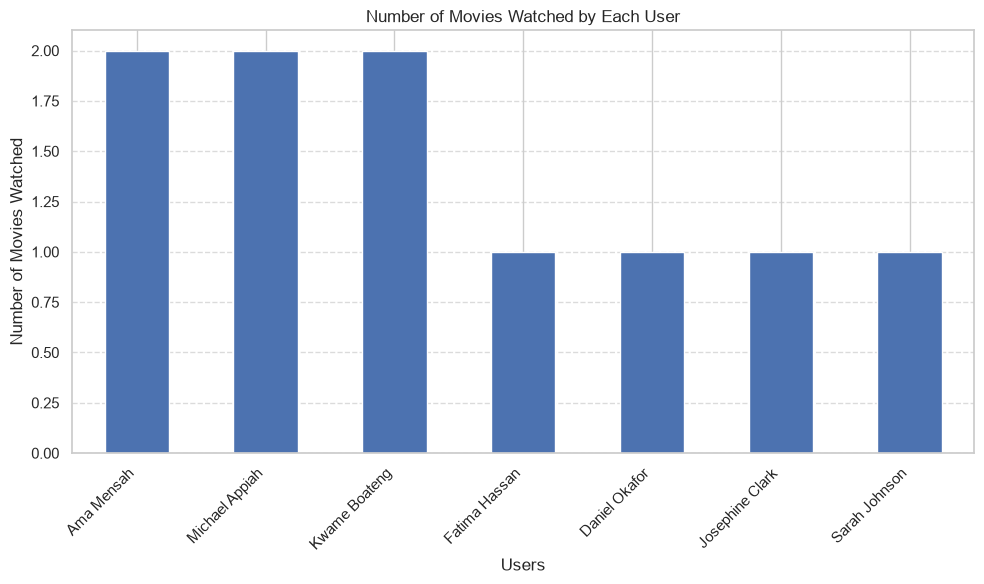

In [28]:
# Calculate the number of movies watched by each user

user_activity = (
    netflix_data.groupby("name")["movie_id"]
    .count()
    .sort_values(ascending=False)
)

# Display user viewing activity
print("User Viewing Activity:")
display(user_activity)

# Create visualization
plt.figure(figsize=(10, 6))

user_activity.plot(kind="bar")

plt.title("Number of Movies Watched by Each User")
plt.xlabel("Users")
plt.ylabel("Number of Movies Watched")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

### 3.6 Interpretation of User Viewing Activity

The analysis shows that Ama Mensah, Michael Appiah, and 
Kwame Boateng recorded the highest viewing activity, 
with two movies each.

Fatima Hassan, Daniel Okafor, Josephine Clark, and 
Sarah Johnson recorded one movie each.

This suggests differences in viewing activity among 
the users in the dataset.

However, the dataset contains only 10 viewing records, 
so these results should not be treated as evidence of 
long-term customer behaviour.

## 4. Business Insights and Key Findings

### 4.1 Key Findings

The analysis of the Netflix dataset produced several important findings:

**1. Overall User Satisfaction**

The overall average user rating was 8.1 out of 10, suggesting generally positive viewing experiences among the users represented in the dataset.

**2. Movie Performance**

Ocean Wonders received the highest individual user rating of 10, while Laugh Out Loud received the lowest rating of 6.

Based on the average movie ratings provided in the dataset, Ocean Wonders recorded the highest average rating of 8.7, followed by Code of Tomorrow with 8.4.

**3. Genre Distribution**

The dataset contains 10 movies across 10 different genres. Each genre is represented by one movie, indicating an even distribution within this sample.

**4. Genre Rating Patterns**

Documentary recorded the highest observed user rating of 10, while Comedy recorded the lowest observed rating of 6. These results represent individual movie observations rather than reliable comparisons of overall genre performance.

**5. User Viewing Activity**

Ama Mensah, Michael Appiah and Kwame Boateng recorded the highest viewing activity, with two movies each. The remaining four users watched one movie each.

### 4.2 Business Implications

The findings provide some useful insights for a streaming platform:

- Maintaining a good selection of highly rated movies could support positive viewing experiences.
- Monitoring individual movie ratings can help identify titles that perform well or may require further review.
- Tracking viewing activity can help platforms understand differences in user engagement.
- Collecting more information about viewing preferences would support better content recommendations.

However, these observations should be treated as preliminary because the dataset contains only 10 users, 10 movies and 10 viewing records.

### 4.3 Business Recommendations

Based on the findings from the analysis, the following recommendations are proposed:

**1. Improve Content Recommendations**

The platform should consider using users' previous viewing activities and ratings to recommend movies that match their interests. This could improve content discovery and viewing experiences.

**2. Monitor Movie Ratings**

The platform should regularly monitor user ratings to identify highly rated movies and titles receiving lower ratings. This information can support content evaluation and future programming decisions.

**3. Encourage User Engagement**

The platform could introduce personalized movie suggestions and viewing reminders to encourage users to explore more content.

**4. Collect More Customer Data**

The company should collect additional viewing records, ratings and customer preferences. A larger dataset would provide more reliable insights into viewing behaviour and customer engagement.

**5. Monitor Genre Preferences**

The platform should continue monitoring the popularity and ratings of different movie genres. More observations across each genre would help identify genuine content preferences.

Overall, implementing these recommendations could help improve content discovery, understand customer preferences and support better business decisions.

### 4.4 Limitations of the Analysis

Although the analysis provided useful insights into movie ratings, genre distribution and user viewing activity, several limitations should be considered.

**1. Small Dataset Size**

The analysis was based on only 10 users, 10 movies and 10 viewing records. This sample is too small to represent the viewing behaviour of a large streaming platform.

**2. Limited Viewing Records**

Each movie has only one recorded viewing observation in the dataset. Therefore, the analysis cannot establish consistent customer preferences or long-term viewing patterns.

**3. Limited Genre Representation**

Each of the 10 movie genres is represented by only one movie. This makes it difficult to determine which genres are generally more popular among users.

**4. Limited Time Coverage**

The viewing records cover a short period in October 2026. Consequently, the analysis cannot identify seasonal viewing patterns or changes in customer behaviour over time.

**5. Limited Customer Behaviour Information**

Although the dataset contains basic customer information, the analysis does not fully explore other factors that could influence viewing decisions, such as customer preferences and viewing frequency over longer periods.

Despite these limitations, the project demonstrates how Python and data analysis techniques can be used to integrate datasets, identify patterns, visualize results and generate preliminary business insights.

## 5. Conclusion

This project successfully demonstrated how Python can be applied to analyse movie ratings, customer information and viewing activities to generate meaningful business insights.

Three datasets (Users, Movies and Watch History) were imported, inspected, cleaned and integrated using the Pandas library. Data quality checks were performed to identify missing values, duplicate records and inconsistencies in data types before the datasets were merged into a single master dataset.

Exploratory Data Analysis was conducted to examine movie popularity, user ratings, genre distribution and customer viewing activity. Five visualizations were developed using Matplotlib and Seaborn to communicate the findings effectively.

The analysis revealed an overall average user rating of 8.1 out of 10. Ocean Wonders recorded the highest individual user rating of 10, while Ama Mensah, Michael Appiah and Kwame Boateng recorded the highest viewing activity, with two movies each.

The findings demonstrate how data analysis can help a streaming platform understand viewing patterns, evaluate movie ratings and identify opportunities to improve content recommendations and customer engagement.

However, the small dataset limits the extent to which the findings can be generalized to a larger streaming population.

Overall, the project strengthened practical understanding of data cleaning, data integration, exploratory data analysis and data visualization using Python. It also demonstrated the importance of transforming raw data into useful information that can support business decision-making.